# Handwritten Math Recognition: CNN

Pipeline: contour segmentation → CNN symbol classifier → layout-aware parser → SymPy solver.

**Quick start:** run all cells. With `TRAIN = False` (the default), the notebook loads `weights/cnn.pth` and runs on the images in `examples/`; no dataset needed.

**Retrain:** download the data with `python scripts/download_data.py`, set `TRAIN = True`, and run all cells (3 epochs).

## Setup

In [1]:
import os
import re
import random

import cv2
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as T
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import ImageFolder
from PIL import Image
from tqdm.auto import tqdm
from sympy.parsing.latex import parse_latex

# ---- Configuration -------------------------------------------------------
TRAIN = False                  # True: retrain from DATA_PATH. False: load WEIGHTS_PATH.
DATA_PATH = 'data'             # one folder per class (see scripts/download_data.py)
WEIGHTS_PATH = 'weights/cnn.pth'
EXAMPLES_DIR = 'examples'
OUTPUT_DIR = 'outputs'         # intermediate images are written here
SHOW_STEPS = True              # plot binarization, boxes and each symbol patch

ALLOWED_CLASSES = ['forward_slash', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9',
                   '+', '-', '(', ')', 'd', 'X', 'int', 'lt', 'leq', 'gt', 'geq', '=', 'neq']
LABELS = sorted(ALLOWED_CLASSES)   # same order ImageFolder assigns
NUM_CLASSES = len(LABELS)
IMG_H, IMG_W = 45, 45
BATCH_SZ = 32
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
os.makedirs(OUTPUT_DIR, exist_ok=True)

if torch.cuda.is_available():
    compute_device = torch.device('cuda')
elif torch.backends.mps.is_available():
    compute_device = torch.device('mps')
else:
    compute_device = torch.device('cpu')
print('Device:', compute_device)
print('Labels:', LABELS)

Device: mps
Labels: ['(', ')', '+', '-', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '=', 'X', 'd', 'forward_slash', 'geq', 'gt', 'int', 'leq', 'lt', 'neq']


In [2]:
# Utility Functions for Image Processing
############################################

def apply_binarization(img):
    if isinstance(img, Image.Image):
        img = np.array(img)
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    # same parameters as training
    thresh = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                                   cv2.THRESH_BINARY, 15, 3)
    return cv2.bitwise_not(thresh)

class AdaptiveBinarization:
    def __call__(self, img):
        arr = np.array(img)
        bin_img = apply_binarization(arr)
        return torch.tensor(bin_img, dtype=torch.float32).unsqueeze(0) / 255.0

## Data (training only)

In [3]:
class FilteredRAMCachedDataset(torch.utils.data.Dataset):
    def __init__(self, root, allowed_classes, transform=None):
        self.dataset = ImageFolder(root)
        self.transform = transform

        # Filter classes
        self.class_to_idx = {
            cls: i for i, cls in enumerate(cls for cls in self.dataset.classes if cls in allowed_classes)
        }
        self.classes = list(self.class_to_idx.keys())

        # Filter and cache images
        self.cached_images = []
        for path, label in tqdm(self.dataset.samples, desc='Caching images'):
            class_name = self.dataset.classes[label]
            if class_name in self.class_to_idx:
                new_label = self.class_to_idx[class_name]
                image = Image.open(path).convert("RGB")
                self.cached_images.append((image, new_label))

    def __len__(self):
        return len(self.cached_images)

    def __getitem__(self, idx):
        image, label = self.cached_images[idx]
        if self.transform:
            image = self.transform(image)
        return image, label

In [4]:
# Data and Transform Setup (only needed for training)
############################################

data_transforms = T.Compose([
    T.Grayscale(),
    T.Resize((IMG_H, IMG_W)),
    AdaptiveBinarization()
])

if TRAIN:
    dataset = FilteredRAMCachedDataset(DATA_PATH, ALLOWED_CLASSES, transform=data_transforms)
    assert dataset.classes == LABELS, f"Missing classes in {DATA_PATH}: {set(LABELS) - set(dataset.classes)}"

    n = len(dataset)
    n_train = int(0.95 * n)
    n_val = n - n_train
    train_ds, val_ds = random_split(dataset, [n_train, n_val],
                                    generator=torch.Generator().manual_seed(SEED))

    pin = compute_device.type == 'cuda'
    train_loader = DataLoader(train_ds, batch_size=BATCH_SZ, shuffle=True, num_workers=0, pin_memory=pin)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SZ, shuffle=False, num_workers=0, pin_memory=pin)
    print(f"Train samples: {len(train_ds)}, Val samples: {len(val_ds)}")
else:
    print("TRAIN is False: skipping dataset loading.")

TRAIN is False: skipping dataset loading.


## Model

In [5]:
# Model Definition (PyTorch)
############################################

class EquationRecognizer(nn.Module):
    def __init__(self, num_classes):
        super(EquationRecognizer, self).__init__()
        # Convolutional layers setup
        self.layer1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.layer2 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.layer3 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.maxpool = nn.MaxPool2d(2)
        self.activation = nn.ReLU()
        # Flattened feature size computed on a 45x45 input after three conv+pool stages
        self.fc1 = nn.Linear(32 * 5 * 5, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.maxpool(self.activation(self.layer1(x)))
        x = self.maxpool(self.activation(self.layer2(x)))
        x = self.maxpool(self.activation(self.layer3(x)))
        x = x.view(x.size(0), -1)
        x = self.activation(self.fc1(x))
        return self.fc2(x)

In [6]:
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=4):
    for epoch in range(1, epochs+1):
        # ——— Training ———
        model.train()
        running_loss = correct = total = 0
        for images, targets in tqdm(train_loader, desc=f"Epoch {epoch}/{epochs} [Train]"):
            images, targets = images.to(compute_device), targets.to(compute_device)
            optimizer.zero_grad()
            outputs = model(images)
            loss    = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            preds       = outputs.argmax(dim=1)
            correct    += (preds == targets).sum().item()
            total      += targets.size(0)

        train_loss = running_loss / total
        train_acc  = correct / total * 100

        # ——— Validation ———
        model.eval()
        val_loss = val_correct = val_total = 0
        with torch.no_grad():
            for images, targets in tqdm(val_loader, desc=f"Epoch {epoch}/{epochs} [Val]  "):
                images, targets = images.to(compute_device), targets.to(compute_device)
                outputs = model(images)
                loss    = criterion(outputs, targets)

                val_loss    += loss.item() * images.size(0)
                preds        = outputs.argmax(dim=1)
                val_correct += (preds == targets).sum().item()
                val_total   += targets.size(0)

        val_loss = val_loss / val_total
        val_acc  = val_correct / val_total * 100

        print(
            f"Epoch {epoch}: "
            f"Train Loss = {train_loss:.4f}, Train Acc = {train_acc:.2f}% | "
            f"Val Loss = {val_loss:.4f}, Val Acc = {val_acc:.2f}%"
        )

    return model

In [7]:
model = EquationRecognizer(NUM_CLASSES).to(compute_device)

if TRAIN:
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    model = train_model(model, train_loader, val_loader, criterion, optimizer, epochs=3)
    os.makedirs(os.path.dirname(WEIGHTS_PATH), exist_ok=True)
    torch.save(model.state_dict(), WEIGHTS_PATH)
    print("Training complete. Saved", WEIGHTS_PATH)
else:
    model.load_state_dict(torch.load(WEIGHTS_PATH, map_location=compute_device, weights_only=True))
    print("Loaded", WEIGHTS_PATH)
model.eval();

Loaded weights/cnn.pth


In [8]:
from sklearn.metrics import classification_report

if TRAIN:
    all_preds, all_labels = [], []
    model.eval()
    with torch.no_grad():
        for imgs, lbls in val_loader:
            out = model(imgs.to(compute_device))
            all_preds.extend(out.argmax(1).cpu().numpy())
            all_labels.extend(lbls.numpy())

    print(classification_report(all_labels, all_preds, target_names=LABELS, digits=4))
    report = classification_report(all_labels, all_preds, target_names=LABELS,
                                   digits=4, output_dict=True)
    cell_text = [[f"{report[c]['precision']:.4f}", f"{report[c]['recall']:.4f}",
                  f"{report[c]['f1-score']:.4f}", f"{int(report[c]['support'])}"] for c in LABELS]
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.axis('off')
    tbl = ax.table(cellText=cell_text, rowLabels=LABELS,
                   colLabels=['Precision', 'Recall', 'F1-score', 'Support'],
                   cellLoc='center', loc='center')
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10)
    tbl.scale(1, 1.5)
    plt.title('Per-Class Classification Report (CNN)')
    plt.show()
else:
    print("TRAIN is False: skipping validation report (needs the dataset).")

TRAIN is False: skipping validation report (needs the dataset).


## Segmentation, recognition and parsing

In [9]:
# Image Processing Functions
############################################

def merge_on_x_overlap(boxes, min_x_overlap_ratio=0.7):
    """
    Merge boxes whose horizontal (x-axis) overlap covers at least
    `min_x_overlap_ratio` of one box's width.
    """
    merged = []
    used   = [False]*len(boxes)

    for i, b1 in enumerate(boxes):
        if used[i]:
            continue
        x1, y1, w1, h1 = b1
        # start a "union" rectangle at b1's bounds
        ux1, uy1 = x1,        y1
        ux2, uy2 = x1 + w1, y1 + h1

        for j, b2 in enumerate(boxes):
            if i == j or used[j]:
                continue
            x2, y2, w2, h2 = b2

            # 1D overlap in x:
            overlap_x = max(0, min(x1+w1, x2+w2) - max(x1, x2))

            # if that overlap covers >= min_x_overlap_ratio of either box's width:
            if overlap_x / w1 >= min_x_overlap_ratio or overlap_x / w2 >= min_x_overlap_ratio:
                used[j] = True
                # expand our union to include b2
                ux1 = min(ux1, x2)
                uy1 = min(uy1, y2)
                ux2 = max(ux2, x2 + w2)
                uy2 = max(uy2, y2 + h2)

        # append the merged (or standalone) box
        merged.append([ux1, uy1, ux2 - ux1, uy2 - uy1])
        used[i] = True

    # if any merges happened, merged list is shorter than original -> recurse
    if len(merged) < len(boxes):
        return merge_on_x_overlap(merged, min_x_overlap_ratio)

    return merged


def clean_binary(img_gray):
    blur = cv2.GaussianBlur(img_gray, (51, 51), 0)
    norm = cv2.divide(img_gray, blur, scale=255)
    th = cv2.adaptiveThreshold(norm, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                               cv2.THRESH_BINARY, 25, 15)
    opened = cv2.morphologyEx(th, cv2.MORPH_OPEN,
                               cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3)))
    return ~opened  # white symbols on black background


def is_symbol_box(box, bin_img, min_area=100, min_density=0.02):
    x, y, w, h = map(int, box)
    if w * h < min_area:
        return False
    patch = bin_img[y:y+h, x:x+w]
    return (np.count_nonzero(patch) / patch.size) > min_density


def find_bounding_boxes(image_path):
    """
    Detect symbol boxes using robust binarization and noise filtering.
    """
    orig = cv2.imread(image_path)
    if orig is None:
        print(f"Failed to read image from {image_path}")
        return []

    gray = cv2.cvtColor(orig, cv2.COLOR_BGR2GRAY) if len(orig.shape) == 3 else orig
    bin_img = clean_binary(gray)

    if SHOW_STEPS:
        plt.imshow(bin_img, cmap='gray')
        plt.title("Binarized for Contour Detection")
        plt.axis('off')
        plt.show()

    contours, _ = cv2.findContours(bin_img, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    boxes = []
    for contour in contours:
        x, y, w, h = cv2.boundingRect(contour)
        if is_symbol_box([x, y, w, h], bin_img):
            boxes.append([x, y, w, h])

    # Sort and merge overlapping boxes
    boxes.sort(key=lambda b: b[0])
    boxes = merge_on_x_overlap(boxes, min_x_overlap_ratio=0.7)
    return boxes


def resize_with_padding(img, target_size, padding_color=255):
    """
    Resize the image to target_size while preserving aspect ratio,
    adding padding as necessary.
    """
    orig_h, orig_w = img.shape[:2]
    target_h, target_w = target_size

    interp_method = cv2.INTER_AREA if orig_h > target_h or orig_w > target_w else cv2.INTER_CUBIC
    ratio = orig_w / orig_h

    if ratio > 1:  # wide image
        new_w = target_w
        new_h = max(1, int(round(new_w / ratio)))
        vertical_pad = (target_h - new_h) / 2
        pad_top, pad_bottom = int(np.floor(vertical_pad)), int(np.ceil(vertical_pad))
        pad_left, pad_right = 0, 0
    elif ratio < 1:  # tall image
        new_h = target_h
        new_w = max(1, int(round(new_h * ratio)))
        horizontal_pad = (target_w - new_w) / 2
        pad_left, pad_right = int(np.floor(horizontal_pad)), int(np.ceil(horizontal_pad))
        pad_top, pad_bottom = 0, 0
    else:  # square image
        new_h, new_w = target_h, target_w
        pad_top = pad_bottom = pad_left = pad_right = 0

    if len(img.shape) == 3 and not isinstance(padding_color, (list, tuple, np.ndarray)):
        padding_color = [padding_color] * 3

    scaled = cv2.resize(img, (new_w, new_h), interpolation=interp_method)
    padded = cv2.copyMakeBorder(scaled, pad_top, pad_bottom, pad_left, pad_right,
                                  borderType=cv2.BORDER_CONSTANT, value=padding_color)
    return padded

In [10]:
# Model Inference and Visualization
############################################

def infer_prediction(net, image_arr):
    """
    Preprocess the image patch and return the predicted label index.
    """
    patch_tensor = torch.tensor(image_arr, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0
    patch_tensor = patch_tensor.to(compute_device)
    with torch.no_grad():
        output = net(patch_tensor)
    _, pred = torch.max(output, 1)
    return pred.item()

def process_test_image(test_path, img_flag=1):
    """
    Process the test image based on the flag.
    img_flag: 1 for handwritten images, 0 for drawn images
    """
    if img_flag == 1:
        original_img = cv2.imread(test_path)
        # Convert the image to binary using thresholding
        _, binary_img = cv2.threshold(original_img, 127, 255, cv2.THRESH_BINARY)
        if SHOW_STEPS:
            plt.imshow(binary_img)
            plt.axis('off')
            plt.show()

        # Save the processed image and then detect bounding boxes
        processed_path = os.path.join(OUTPUT_DIR, 'processed.png')
        cv2.imwrite(processed_path, binary_img)
        boxes_found = find_bounding_boxes(processed_path)
        print("Number of boxes detected:", len(boxes_found))
        return processed_path, boxes_found, binary_img
    else:
        original_img = cv2.imread(test_path, 0)
        boxes_found = find_bounding_boxes(test_path)
        print("Number of boxes detected:", len(boxes_found))
        return test_path, boxes_found, original_img

def visualize_boxes(img_path, boxes):
    """
    Draw bounding boxes on the image for visualization.
    """
    temp_copy = cv2.imread(img_path).copy()
    for (x, y, w, h) in boxes:
        xi, yi, wi, hi = map(int, (x, y, w, h))
        cv2.rectangle(temp_copy, (xi, yi), (xi + wi, yi + hi), (0, 0, 255), 1)
    plt.imshow(cv2.cvtColor(temp_copy, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()

def recognize_equation(model, img_path, boxes):
    """
    Recognize the equation from the image using the model.
    """
    raw_gray = cv2.imread(img_path, 0)
    processed_img = apply_binarization(raw_gray)

    eq_symbols = []
    for (x, y, w, h) in sorted(boxes, key=lambda b: b[0]):
        xi, yi, wi, hi = map(int, (x, y, w, h))
        patch_crop = processed_img[yi:yi+hi, xi:xi+wi]
        patch = resize_with_padding(patch_crop, (45, 45), 0)

        if SHOW_STEPS:
            plt.figure(figsize=(1, 1))
            plt.imshow(patch, cmap='gray')
            plt.axis('off')
            plt.show()

        # Decimal-dot override based on white-ink ratio
        white_ratio = np.count_nonzero(patch > 128) / patch.size
        print(f"Box {(xi,yi,wi,hi)} white_ratio={white_ratio:.2f}", end=" -> ")
        if white_ratio > 0.3:
            eq_symbols.append('*')
            print('*')
            continue

        # Otherwise, classify with the model
        sym = LABELS[infer_prediction(model, patch)]
        if sym == 'X': sym = 'x'
        if sym == 'forward_slash': sym = 'div'
        eq_symbols.append(sym)
        print(f"model -> {sym}")

    return eq_symbols

def build_with_exponents(boxes, symbols, size_ratio=0.7, vert_overlap=0.0):
    """
    boxes:      list of [x,y,w,h] sorted left->right
    symbols:    list of str, same order
    size_ratio: max height ratio to the *previous normal* box to qualify as "small"
    vert_overlap: how much higher its top must sit relative to the previous normal box's top
                  (positive means strictly above, negative allows some overlap)
    """
    parts = []
    last_norm_h   = None
    last_norm_top = None  # y coordinate

    i = 0
    while i < len(symbols):
        x, y, w, h = boxes[i]
        sym = symbols[i]

        if last_norm_h is None:
            parts.append(sym)
            last_norm_h, last_norm_top = h, y
            i += 1
            continue

        small_enough = h < last_norm_h * size_ratio
        above_enough = y <= last_norm_top + vert_overlap  # smaller y = higher on the page

        if small_enough and above_enough:
            # treat as superscript; group consecutive superscripts
            exp_syms = []
            while (i < len(symbols)
                   and boxes[i][3] < last_norm_h * size_ratio
                   and boxes[i][1] <= last_norm_top + vert_overlap):
                exp_syms.append(symbols[i])
                i += 1
            exponent = "".join(exp_syms)
            if len(exp_syms) > 1 and not (exponent.startswith('(') and exponent.endswith(')')):
                exponent = f"({exponent})"   # keep 5^(8-4) from becoming 5^8-4
            parts.append("^" + exponent)
        else:
            parts.append(sym)
            last_norm_h, last_norm_top = h, y
            i += 1

    return "".join(parts)

def process_equation_image(image_path, img_flag=1):
    processed_path, boxes_found, _ = process_test_image(image_path, img_flag)
    if SHOW_STEPS:
        visualize_boxes(processed_path, boxes_found)
    eq_symbols = recognize_equation(model, processed_path, boxes_found)
    boxes_sorted = sorted(boxes_found, key=lambda b: b[0])
    equation = build_with_exponents(boxes_sorted, eq_symbols)
    return equation, eq_symbols

def tokenize(equation):
    multi = r'int|leq|geq|lt|gt|neq|div'
    rest  = r'\^|\d+|[A-Za-z]|[()=+\-*/]'
    return re.findall(rf'{multi}|{rest}', equation)

## Solver

In [11]:
# Symbolic Solver
############################################

from sympy.parsing.sympy_parser import (parse_expr, standard_transformations,
                                        implicit_multiplication_application)

x, y = sp.symbols('x y')
SYMS = {'x': x, 'y': y}
TRANSFORMS = standard_transformations + (implicit_multiplication_application,)

def to_sympy(expr):
    """Parse a string like '5+2x' (implicit multiplication allowed)."""
    return parse_expr(expr, local_dict=SYMS, transformations=TRANSFORMS)

def tokens_to_latex(tokens):
    """Build a LaTeX string from the token list."""
    out, i, L = [], 0, len(tokens)
    while i < L:
        t = tokens[i]
        # derivative: d div d x ( expr )
        if i+3 < L and tokens[i]=='d' and tokens[i+1]=='div' \
                      and tokens[i+2]=='d' and tokens[i+3] in ('x','y'):
            var = tokens[i+3]; i += 4
            inner = ''.join(tokens[i:])  # rest is argument
            out.append(f"\\frac{{d}}{{d{var}}}({inner})")
            break
        # integral: int <expr> d x
        if t == 'int':
            j = tokens.index('d', i+1)
            integrand = ''.join(tokens[i+1:j])
            var = tokens[j+1]
            out.append(f"\\int {integrand}\\,d{var}")
            i = j+2
            continue
        # fraction: a div b -> \frac{a}{b}
        if t == 'div' and out:
            num = out.pop()
            den = tokens[i+1] if i+1 < L else ''
            out.append(f"\\frac{{{num}}}{{{den}}}")
            i += 2
            continue
        # simple maps
        if t == 'times': out.append('\\times')
        elif t == 'dot':  out.append('.')
        elif t == 'leq':  out.append(r'\leq')
        elif t == 'geq':  out.append(r'\geq')
        elif t == 'neq':  out.append(r'\neq')
        elif t == 'lt':   out.append('<')
        elif t == 'gt':   out.append('>')
        elif t == 'ne':   out.append(r'\neq')
        else:             out.append(t)
        i += 1
    return ''.join(out)

def clean_latex(latex: str) -> str:
    # x^(3) -> x^{3}
    latex = re.sub(r'\^\(([^)]+)\)', r'^{\1}', latex)
    # collapse double-parens on derivative
    latex = re.sub(
        r'(\\frac\{d\}\{d[xy]\})\(?\(?(.+?)\)?\)?$',
        lambda m: f"{m.group(1)}({m.group(2)})",
        latex
    )
    return latex

def solve_tokens(eq_symbols):
    clean = clean_latex(tokens_to_latex(eq_symbols))

    # 1) DERIVATIVE?
    m = re.match(r'\\frac\{d\}\{d([xy])\}\((.+)\)$', clean)
    if m:
        var, inner = m.groups()
        expr = re.sub(r'[{}]', '', inner).replace('^', '**')
        res = sp.diff(to_sympy(expr), SYMS[var])
        return res, res

    # 2) INTEGRAL?
    m = re.match(r'\\int\s*(.+)\\,d([xy])$', clean)
    if m:
        inner, var = m.groups()
        expr = re.sub(r'[{}]', '', inner).replace('^', '**')
        res = sp.integrate(to_sympy(expr), (SYMS[var],))
        return res, res

    # 3) COMPARISON (has <, >, <=, >=, !=)
    comp_ops = [('\\leq', sp.LessThan), ('\\geq', sp.GreaterThan), ('\\neq', sp.Unequality),
                ('<', sp.StrictLessThan), ('>', sp.StrictGreaterThan)]
    for latex_op, rel_cls in comp_ops:
        if latex_op in clean:
            lhs, rhs = clean.split(latex_op, 1)
            lhs = re.sub(r'[{}]', '', lhs).replace('^', '**')
            rhs = re.sub(r'[{}]', '', rhs).replace('^', '**')
            rel = rel_cls(to_sympy(lhs), to_sympy(rhs))
            return rel, sp.simplify(rel)

    # 4) EQUATION (has =)
    if '=' in clean:
        lhs, rhs = clean.split('=', 1)
        lhs = re.sub(r'[{}]', '', lhs).replace('^', '**')
        rhs = re.sub(r'[{}]', '', rhs).replace('^', '**')
        sol = sp.solve(sp.Eq(to_sympy(lhs), to_sympy(rhs)), x)
        return sol, sol

    # 5) PURE NUMERIC ARITHMETIC?
    if re.fullmatch(r'[\d\+\-\*/\.\^]+', clean):
        res = to_sympy(clean.replace('^', '**'))
        return res, res

    # 6) FALLBACK: parse the LaTeX with SymPy and simplify (e.g. fractions)
    ast = parse_latex(clean)
    return ast, sp.latex(sp.simplify(ast))

## Try it

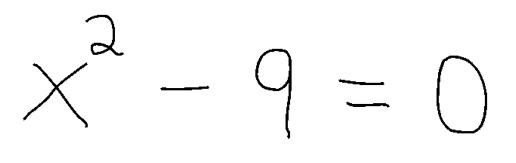

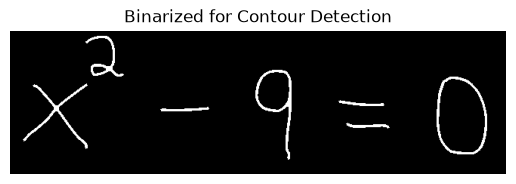

Number of boxes detected: 6


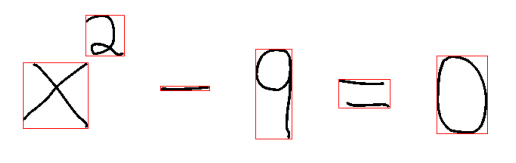

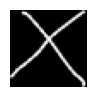

Box (17, 70, 86, 87) white_ratio=0.10 -> model -> x


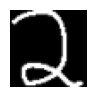

Box (100, 7, 51, 54) white_ratio=0.16 -> model -> 2


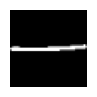

Box (199, 101, 65, 6) white_ratio=0.05 -> model -> -


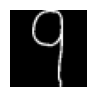

Box (325, 52, 48, 119) white_ratio=0.06 -> model -> 9


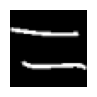

Box (435, 92, 68, 38) white_ratio=0.09 -> model -> =


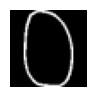

Box (565, 61, 67, 103) white_ratio=0.09 -> model -> 0
Equation: x^2-9=0
Tokens:   ['x', '^', '2', '-', '9', '=', '0']
LaTeX:    x^2-9=0
Result:   [-3, 3]


In [12]:
# Test Image Input and Equation Recognition
############################################

# img_flag: 1 for handwritten photos/scans, 0 for clean digital drawings
img_flag = 1
test_path = os.path.join(EXAMPLES_DIR, 'quadratic.png')

equation, _ = process_equation_image(test_path, img_flag)
tokens = tokenize(equation)

print("Equation:", equation)
print("Tokens:  ", tokens)
print("LaTeX:   ", clean_latex(tokens_to_latex(tokens)))
print("Result:  ", solve_tokens(tokens)[1])

In [13]:
# Run every image in examples/ (without the step-by-step plots)
############################################

SHOW_STEPS = False
for name in sorted(os.listdir(EXAMPLES_DIR)):
    if not name.lower().endswith(('.png', '.jpg', '.jpeg')):
        continue
    print(f"\n=== {name} ===")
    equation, _ = process_equation_image(os.path.join(EXAMPLES_DIR, name), img_flag=1)
    tokens = tokenize(equation)
    try:
        result = solve_tokens(tokens)[1]
    except Exception as e:
        result = f"could not solve ({type(e).__name__})"
    print(f"Equation: {equation}  ->  {result}")
SHOW_STEPS = True


=== addition.png ===
Number of boxes detected: 3
Box (100, 77, 25, 151) white_ratio=0.06 -> model -> 1
Box (190, 96, 155, 139) white_ratio=0.13 -> model -> +
Box (375, 66, 165, 213) white_ratio=0.09 -> model -> 3
Equation: 1+3  ->  4

=== exponent.png ===
Number of boxes detected: 6
Box (151, 209, 298, 497) white_ratio=0.03 -> model -> 4
Box (507, 73, 58, 208) white_ratio=0.04 -> model -> (
Box (589, 89, 79, 154) white_ratio=0.09 -> model -> 3
Box (741, 123, 118, 102) white_ratio=0.12 -> model -> +
Box (905, 75, 116, 164) white_ratio=0.10 -> model -> 5
Box (1065, 39, 49, 223) white_ratio=0.03 -> model -> )


Equation: 4^(3+5)  ->  65536

=== fraction.png ===


Number of boxes detected: 3


Box (0, 90, 368, 447) white_ratio=0.11 -> 

model -> 3
Box (490, 120, 378, 354) white_ratio=0.05 -> model -> div
Box (963, 82, 308, 543) white_ratio=0.06 -> model -> 3
Equation: 3div3  ->  1

=== inequality.png ===


Number of boxes detected: 4
Box (91, 107, 30, 518) white_ratio=0.03 -> model -> 1
Box (323, 115, 300, 480) white_ratio=0.08 -> model -> 3
Box (931, 157, 357, 488) white_ratio=0.07 -> model -> gt
Box (1516, 144, 213, 499) white_ratio=0.08 -> model -> 6
Equation: 13gt6  ->  True

=== inequality_geq.png ===
Number of boxes detected: 7
Box (72, 230, 134, 18) white_ratio=0.06 -> model -> -
Box (364, 136, 111, 183) white_ratio=0.09 -> model -> 6
Box (610, 172, 130, 101) white_ratio=0.11 -> model -> +
Box (819, 114, 132, 141) white_ratio=0.11 -> model -> 7
Box (1086, 124, 115, 210) white_ratio=0.06 -> model -> geq
Box (1274, 182, 76, 14) white_ratio=0.10 -> model -> -
Box (1423, 93, 77, 184) white_ratio=0.09 -> model -> 9
Equation: -6+7geq-9  ->  True

=== integral.png ===
Number of boxes detected: 9
Box (144, 88, 208, 359) white_ratio=0.03 -> model -> int
Box (443, 98, 108, 364) white_ratio=0.02 -> model -> (
Box (585, 163, 172, 240) white_ratio=0.06 -> model -> 5
Box (851, 204, 172, 134) wh

model -> -
Box (939, 23, 33, 121) white_ratio=0.06 -> model -> 1
Equation: 4^2+3^(-1)  ->  \frac{49}{3}

=== parentheses.png ===


Number of boxes detected: 7
Box (115, 88, 188, 588) white_ratio=0.02 -> model -> (
Box (291, 225, 309, 334) white_ratio=0.08 -> model -> 7
Box (745, 377, 184, 15) white_ratio=0.07 -> model -> -
Box (1062, 196, 260, 356) white_ratio=0.10 -> model -> 5
Box (1325, 104, 143, 560) white_ratio=0.02 -> model -> )
Box (1590, 414, 29, 25) white_ratio=0.66 -> *
Box (1743, 131, 257, 547) white_ratio=0.04 -> model -> 9
Equation: (7-5)*9  ->  18

=== quadratic.png ===


Number of boxes detected: 6
Box (17, 70, 86, 87) white_ratio=0.10 -> model -> x
Box (100, 7, 51, 54) white_ratio=0.16 -> model -> 2
Box (199, 101, 65, 6) white_ratio=0.05 -> model -> -
Box (325, 52, 48, 119) white_ratio=0.06 -> model -> 9
Box (435, 92, 68, 38) white_ratio=0.09 -> model -> =
Box (565, 61, 67, 103) white_ratio=0.09 -> model -> 0
Equation: x^2-9=0  ->  [-3, 3]

=== subtraction.png ===
Number of boxes detected: 4
Box (201, 167, 366, 430) white_ratio=0.08 -> model -> 4
Box (709, 166, 326, 462) white_ratio=0.07 -> model -> 4
Box (1179, 334, 268, 45) white_ratio=0.06 -> model -> -
Box (1571, 153, 287, 454) white_ratio=0.08 -> model -> 3
Equation: 44-3  ->  41
